# 01 · Limpieza: de los archivos crudos a la tabla por estación y hora

Proyecto CityBykeNY (DataRush). Citi Bike publica un archivo de viajes por mes. Aquí se muestra
cómo esos archivos se convierten en `station_hour`, la tabla con una fila por estación y hora en
hora local de Nueva York, y qué se encontró al limpiar.

Los datos solo registran viajes que sí ocurrieron (**demanda atendida**). Un cero significa que
no hubo viajes, no que nadie quisiera uno.

## Cómo reproducir desde cero

Desde la raíz del repositorio, con el entorno activado (Python 3.12), en este orden:

```bash
python3.12 -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt -c constraints.txt

python scripts/download_trips.py --desde 202607 --hasta 202609   # unos 3 GB, a data/raw/trips
python scripts/freeze_gbfs.py            # SOLO si falta config/gbfs_congelado.csv (necesita una captura de GBFS)
python scripts/build_tables.py           # limpieza: stations, station_hour, routes y trips
python scripts/run_baseline.py           # promedio histórico: predictions y métricas de validación
python scripts/run_lgbm.py               # LightGBM con cuantiles: predictions y métricas de validación
python scripts/run_simulation.py         # simulación en validación: recommendations y policy_curve
python scripts/run_piso_wape.py          # piso del WAPE y métricas por franja, en validación
```



Este notebook **no recalcula nada pesado**: lee `data/processed` y los reportes de
`data/processed/reports` que dejaron esos comandos, y muestra tablas y gráficas. El paso que corresponde a este notebook es `python scripts/build_tables.py` (`src/data/build_tables.py`), que tarda unos 20 segundos y deja su reporte en `limpieza.md` y `limpieza.json`.
Para volver a ejecutarlo: `python -m jupyter nbconvert --to notebook --execute --inplace notebooks/01_limpieza.ipynb`.

In [1]:
# Raíz del repositorio: funciona si el notebook se abre desde notebooks/ o desde la raíz.
import json
import os
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(RAIZ))
os.chdir(RAIZ)  # las rutas relativas (config/, data/) se resuelven desde la raíz

import duckdb
import pandas as pd
from IPython.display import Markdown, display

from src.paths import DATA_PROCESSED, DATA_RAW, REPORTS, TZ

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", None)


def leer_json(ruta):
    return json.loads(Path(ruta).read_text(encoding="utf-8"))


def miles(v, dec=0):
    return f"{v:,.{dec}f}"


def pct(v, dec=1):
    return f"{100 * v:.{dec}f} %"


print("Raíz:", RAIZ.name, "| zona horaria:", TZ)

Raíz: CityBykeNY | zona horaria: America/New_York


In [2]:
# Gráficas: el entorno del proyecto no trae matplotlib, así que se dibujan con Pillow
# y quedan como PNG dentro del notebook (se ven en GitHub sin ejecutar nada).
import io
import math

from IPython.display import Image as PNG
from PIL import Image, ImageDraw, ImageFont

TINTA, GRIS, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
AZUL, NARANJA, VERDE, NEUTRO = "#2a78d6", "#eb6834", "#1baf7a", "#898781"


def fuente(puntos):
    """Una fuente del sistema con acentos; si no hay ninguna, la de Pillow (que no los trae)."""
    for nombre in ("Arial.ttf", "DejaVuSans.ttf", "Helvetica.ttc", "LiberationSans-Regular.ttf", "arial.ttf"):
        try:
            return ImageFont.truetype(nombre, puntos)
        except OSError:
            continue
    return ImageFont.load_default(size=puntos)


def grafica(series, titulo, eje_x, eje_y, marcas_x, lineas_v=(), lineas_h=(), en_pct=False, ancho=860, alto=400):
    """Líneas sobre un solo eje que empieza en cero.

    series: lista de dicts con nombre, x, y, color y, si hay intervalo, bajo y alto.
    marcas_x: lista de (valor, texto). lineas_v y lineas_h: listas de (valor, texto).
    """
    k = 2  # se dibuja al doble para que se vea nítido
    W, H = ancho * k, alto * k
    img = Image.new("RGB", (W, H), FONDO)
    d = ImageDraw.Draw(img)
    f_t, f_n = fuente(15 * k), fuente(12 * k)
    izq, der, arr, aba = 80 * k, 30 * k, 84 * k, 58 * k
    xs = [float(v) for s in series for v in s["x"]]
    ys = [float(v) for s in series for c in ("y", "bajo", "alto") for v in s.get(c, [])] + [float(h) for h, _ in lineas_h]
    x0, x1, y1 = min(xs), max(xs), max(ys) * 1.08
    paso = 10 ** math.floor(math.log10(y1 / 4))
    paso *= next(m for m in (1, 2, 5, 10) if y1 / (paso * m) <= 6)
    px = lambda x: izq + (float(x) - x0) / (x1 - x0) * (W - izq - der)
    py = lambda y: H - aba - float(y) / y1 * (H - arr - aba)
    texto = (lambda v: f"{100 * v:.0f} %") if en_pct else (lambda v: f"{v:,.0f}" if paso >= 1 else f"{v:,.2f}")

    d.text((izq, 10 * k), titulo, fill=TINTA, font=f_t)
    lx = izq
    for s in series:
        d.line([(lx, 44 * k), (lx + 18 * k, 44 * k)], fill=s["color"], width=3 * k)
        d.text((lx + 24 * k, 36 * k), s["nombre"], fill=GRIS, font=f_n)
        lx += 24 * k + d.textlength(s["nombre"], font=f_n) + 22 * k
    d.text((izq, arr - 22 * k), eje_y, fill=GRIS, font=f_n)

    for i in range(int(y1 / paso) + 1):
        v = i * paso
        d.line([(izq, py(v)), (W - der, py(v))], fill=REJILLA if i else "#c3c2b7", width=k)
        t = texto(v)
        d.text((izq - 8 * k - d.textlength(t, font=f_n), py(v) - 8 * k), t, fill=GRIS, font=f_n)
    for v, t in marcas_x:
        d.line([(px(v), H - aba), (px(v), H - aba + 4 * k)], fill="#c3c2b7", width=k)
        d.text((px(v) - d.textlength(t, font=f_n) / 2, H - aba + 8 * k), t, fill=GRIS, font=f_n)
    d.text(((izq + W - der) / 2 - d.textlength(eje_x, font=f_n) / 2, H - 24 * k), eje_x, fill=GRIS, font=f_n)
    for v, t in lineas_v:
        d.line([(px(v), arr), (px(v), H - aba)], fill=NEUTRO, width=k)
        d.text((px(v) + 5 * k, arr + 2 * k), t, fill=GRIS, font=f_n)
    for v, t in lineas_h:
        d.line([(izq, py(v)), (W - der, py(v))], fill=NEUTRO, width=k)
        d.text((izq + 8 * k, py(v) + 5 * k), t, fill=GRIS, font=f_n)

    for i, s in enumerate(series):
        puntos = [(px(x), py(y)) for x, y in zip(s["x"], s["y"])]
        if "bajo" in s:  # intervalo: bigote vertical, corrido unos pixeles para que no se tapen entre series
            corr = (i - (len(series) - 1) / 2) * 5 * k
            for x, lo, hi in zip(s["x"], s["bajo"], s["alto"]):
                d.line([(px(x) + corr, py(lo)), (px(x) + corr, py(hi))], fill=s["color"], width=k)
                for y in (lo, hi):
                    d.line([(px(x) + corr - 3 * k, py(y)), (px(x) + corr + 3 * k, py(y))], fill=s["color"], width=k)
        if len(puntos) > 1:
            d.line(puntos, fill=s["color"], width=2 * k, joint="curve")
        if len(puntos) <= 31:
            for x, y in puntos:
                d.ellipse([x - 5 * k, y - 5 * k, x + 5 * k, y + 5 * k], fill=s["color"], outline=FONDO, width=k)

    salida = io.BytesIO()
    img.save(salida, format="PNG", optimize=True)
    display(PNG(data=salida.getvalue(), width=ancho))

## 1. Periodo y tramos

El periodo, los tres tramos y las reglas de limpieza no están en el código: están en
`config/datos.yaml` y se leen con `src.data.datos_config.load_datos()`.

In [3]:
from src.data.datos_config import load_datos

datos = load_datos()
limpieza = leer_json(REPORTS / "limpieza.json")

filas = [("periodo completo", datos.periodo)] + list(datos.tramos.items())
display(pd.DataFrame(
    [{"tramo": n, "primer día": str(t.inicio), "último día (incluido)": str(t.fin), "días": (t.fin - t.inicio).days + 1} for n, t in filas]
).set_index("tramo"))
print("Meses crudos:", ", ".join(datos.meses_crudos))
print("Unión de ids: misma coordenada con tolerancia de", datos.distancia_maxima_m, "m")
print("Excluidas: prefijos", list(datos.prefijos_excluidos), "e ids", list(datos.ids_excluidos))

,primer día,último día (incluido),días
tramo,,,
periodo completo,2026-07-01,2026-09-29,91
entrenamiento,2026-07-01,2026-08-31,62
validacion,2026-09-01,2026-09-14,14
prueba,2026-09-15,2026-09-29,15


Meses crudos: 202607, 202608, 202609
Unión de ids: misma coordenada con tolerancia de 1.0 m
Excluidas: prefijos ['HB', 'JC', 'SYS'] e ids ['1234.56', 'Shop Morgan']


## 2. Archivos crudos

`scripts/download_trips.py` deja un Parquet por mes en `data/raw/trips`, con las 13 columnas del
origen y sin limpiar. Aquí solo se cuentan filas (DuckDB lo resuelve con los metadatos del
archivo) y se comparan con lo que leyó la limpieza.

In [4]:
con = duckdb.connect()
con.execute(f"SET TimeZone='{TZ}'")  # la zona de sesión de DuckDB es la de la computadora, no Nueva York

crudos = DATA_RAW / "trips"
hay_crudos = all((crudos / f"{m}.parquet").exists() for m in datos.meses_crudos)
tabla = pd.DataFrame(limpieza["entradas"]["archivos"]).rename(columns={"filas": "filas según limpieza.json"})
if hay_crudos:
    tabla["filas contadas ahora"] = [
        con.execute(f"SELECT count(*) FROM '{crudos / (m + '.parquet')}'").fetchone()[0] for m in tabla["mes"]
    ]
    columnas = con.execute(f"DESCRIBE SELECT * FROM '{crudos / (datos.meses_crudos[0] + '.parquet')}'").df()
    print("Columnas del crudo:", ", ".join(f"{c} ({t})" for c, t in zip(columnas["column_name"], columnas["column_type"])))
else:
    print("data/raw/trips no está en esta máquina: se muestran solo los conteos del reporte.")
display(tabla.set_index("mes"))
print("Total leído:", miles(limpieza["filas"]["leidas"]), "viajes")

Columnas del crudo: ride_id (VARCHAR), rideable_type (VARCHAR), started_at (TIMESTAMP), ended_at (TIMESTAMP), start_station_name (VARCHAR), start_station_id (VARCHAR), end_station_name (VARCHAR), end_station_id (VARCHAR), start_lat (DOUBLE), start_lng (DOUBLE), end_lat (DOUBLE), end_lng (DOUBLE), member_casual (VARCHAR)


,archivo,filas según limpieza.json,filas contadas ahora
mes,,,
202607,data/raw/trips/202607.parquet,4993137,4993137
202608,data/raw/trips/202608.parquet,5246236,5246236
202609,data/raw/trips/202609.parquet,4982855,4982855


Total leído: 15,222,228 viajes


## 3. Qué se quitó y por qué

Reglas (`src/data/build_tables.py`):

1. Un viaje cuenta una sola vez (`ride_id`), aunque venga en dos archivos.
2. Los ids de estación son texto (los ceros finales importan); solo se les quitan espacios.
3. Las salidas se cuentan en la hora de `started_at` y las llegadas en la hora de `ended_at`,
   cada una en su estación.
4. **Puntas vacías:** un viaje sin estación de inicio o de fin cuenta solo del lado que sí la
   tiene. No se adivina la estación a partir del nombre.

In [5]:
f = limpieza["filas"]
display(pd.DataFrame(
    {"viajes": [f["leidas"], f["duplicadas_quitadas"], f["sin_fecha"], f["terminan_antes_de_empezar"], f["conservadas"]]},
    index=["leídos", "repetidos (ride_id) quitados", "sin fecha", "terminan antes de empezar", "conservados"],
).map(miles))

nombres = {"contadas": "se contó en las tablas", "sin_estacion": "no trae estación (punta vacía)",
           "excluidas": "estación excluida", "fuera_del_periodo": "su fecha cae fuera del periodo"}
puntas = pd.DataFrame({"salidas": limpieza["puntas"]["inicio"], "llegadas": limpieza["puntas"]["fin"]}).loc[list(nombres)]
puntas.index = [nombres[i] for i in puntas.index]
puntas.loc["total (viajes conservados)"] = puntas.sum()
display(puntas.map(miles))
print("Llegadas con nombre de estación pero sin id (no se cuentan):", miles(limpieza["llegadas_con_nombre_pero_sin_id"]))

,viajes
leídos,"15,222,228"
repetidos (ride_id) quitados,0
sin fecha,0
terminan antes de empezar,0
conservados,"15,222,228"


,salidas,llegadas
se contó en las tablas,"15,017,726","14,981,442"
no trae estación (punta vacía),"8,706","44,003"
estación excluida,"2,540","3,702"
su fecha cae fuera del periodo,"193,256","193,081"
total (viajes conservados),"15,222,228","15,222,228"


Llegadas con nombre de estación pero sin id (no se cuentan): 3,039


No se quitó ningún viaje completo: no hubo repetidos ni fechas imposibles. Lo que cambia es qué
**puntas** cuentan. Las salidas y las llegadas no suman lo mismo ni tienen por qué: hay cinco
veces más viajes sin estación de fin que sin estación de inicio, y los viajes que cruzan el borde
del periodo cuentan en una sola punta.

## 4. Estaciones escritas de dos formas

En el origen una misma estación aparece a veces con dos ids (`2231.1` y `2231.10`, o `5308.04` y
`5308.04_`). La escritura de un decimal aparece casi solo en las llegadas, así que sin unirlas el
flujo neto de esas estaciones sale mal. Regla: se unen **solo si coinciden el nombre y la
coordenada**; queda la escritura con más viajes.

In [6]:
u = limpieza["union_de_ids"]
print(f"Grupos de ids parecidos: {u['grupos_encontrados']}. Unidos: {u['grupos_unidos']}. Sin unir: {u['grupos_no_unidos']}.")
print(f"Cambiaron de id {miles(u['salidas_que_cambiaron_de_id'])} salidas y {miles(u['llegadas_que_cambiaron_de_id'])} llegadas.")


def variantes(grupos):
    return pd.DataFrame([
        {"id que queda": g["id_que_queda"], "escritura": v["id"], "nombre": v["nombre"], "salidas": miles(v["salidas"]),
         "llegadas": miles(v["llegadas"]), "distancia (m)": v["distancia_m"], "motivo": v["motivo"] or ""}
        for g in grupos for v in g["variantes"]
    ])


print("\nLos 3 grupos que NO se unieron (quedan como estaciones aparte):")
display(variantes(u["lista_no_unidos"]).set_index("id que queda"))
print("Ejemplo de grupos unidos (los 3 primeros de 95):")
display(variantes(u["lista_unidos"][:3]).drop(columns="motivo").set_index("id que queda"))

Grupos de ids parecidos: 98. Unidos: 95. Sin unir: 3.
Cambiaron de id 826 salidas y 205,130 llegadas.

Los 3 grupos que NO se unieron (quedan como estaciones aparte):


,escritura,nombre,salidas,llegadas,distancia (m),motivo
id que queda,,,,,,
5303.06,5303.06,Clinton St & Grand St,"25,705","25,711",NaN,
5303.06,5303.06_,Clinton St & Grand St,"5,925","5,985",16.2,coordenadas a 16.2 m (máximo 1 m)
6517.08,6517.08,W 42 St & 6 Ave,"20,859","20,605",NaN,
6517.08,6517.08_,W 42 St & 6 Ave,653,652,12.3,coordenadas a 12.3 m (máximo 1 m)
6569.09,6569.09,W 35 St & 9 Ave,"11,684","11,628",NaN,
6569.09,6569.09_,W 35 St & 9 Ave,201,200,32.9,coordenadas a 32.9 m (máximo 1 m)


Ejemplo de grupos unidos (los 3 primeros de 95):


,escritura,nombre,salidas,llegadas,distancia (m)
id que queda,,,,,
2231.10,2231.1,3 Ave & 92 St,0,91,0.0
2231.10,2231.10,3 Ave & 92 St,607,522,NaN
2506.10,2506.1,83 St & Narrows Ave,0,17,0.0
2506.10,2506.10,83 St & Narrows Ave,339,347,NaN
3113.10,3113.1,Stratford Rd & Beverley Rd,0,34,0.0
3113.10,3113.10,Stratford Rd & Beverley Rd,608,580,NaN


## 5. Estaciones excluidas

Nueva Jersey (`HB`, `JC`) solo aparece aquí como destino: sus salidas están en otros archivos y
su flujo quedaría incompleto. `SYS...`, `Shop Morgan` y `1234.56` son talleres o bodegas, no
estaciones públicas. La otra punta del viaje sigue contando.

In [7]:
display(pd.DataFrame(limpieza["estaciones_excluidas"]).drop(columns="ids").rename(
    columns={"salidas": "salidas que no se cuentan", "llegadas": "llegadas que no se cuentan"}).set_index("regla"))

,estaciones,salidas que no se cuentan,llegadas que no se cuentan
regla,,,
id 1234.56,1,1048,1426
id Shop Morgan,1,63,150
prefijo HB,30,0,508
prefijo JC,43,0,496
prefijo SYS,3,1429,1122


## 6. Zona horaria, comprobada con un viaje conocido

`started_at` y `ended_at` vienen en hora local de Nueva York **sin zona**. La zona de sesión de
DuckDB es la de la computadora, así que un `CAST` a secas desplaza las horas. `ts_hour` se
construye con `date_trunc('hour', started_at) AT TIME ZONE 'America/New_York'`.

Comprobación con el viaje `0005122465C6A4A8`: sale a las 08:20:16 del 15 de julio de la estación
`4327.09`. Debe caer en la fila de las 08:00 de Nueva York, que son las 12:00 UTC.

In [8]:
VIAJE, ESTACION = "0005122465C6A4A8", "4327.09"
if hay_crudos:
    display(con.execute(
        f"SELECT ride_id, started_at, ended_at, start_station_id, end_station_id FROM '{crudos / '202607.parquet'}' WHERE ride_id = ?",
        [VIAJE]).df().set_index("ride_id"))
    aparte = con.execute(
        f"SELECT count(*) FROM '{crudos / '202607.parquet'}' WHERE start_station_id = ? AND started_at >= '2026-07-15 08:00:00' AND started_at < '2026-07-15 09:00:00'",
        [ESTACION]).fetchone()[0]
    print("Salidas de esa estación en esa hora, contadas aparte sobre el archivo crudo:", aparte)
fila = con.execute(f"""
    SELECT station_id, strftime(ts_hour, '%Y-%m-%d %H:%M %z') AS hora_nueva_york,
           strftime(ts_hour AT TIME ZONE 'UTC', '%Y-%m-%d %H:%M') AS hora_utc, departures
    FROM '{DATA_PROCESSED / 'station_hour.parquet'}'
    WHERE station_id = ? AND ts_hour = TIMESTAMPTZ '2026-07-15 08:00:00-04'""", [ESTACION]).df()
display(fila.set_index("station_id"))

print("Además, la limpieza revisa un viaje por mes en cada corrida (cálculo aparte, sin la base de datos):")
display(pd.DataFrame(limpieza["zona_horaria"])[
    ["mes", "ride_id", "started_at", "estacion", "hora_nueva_york", "hora_utc", "coincide"]].set_index("mes"))

,started_at,ended_at,start_station_id,end_station_id
ride_id,,,,
0005122465C6A4A8,2026-07-15 08:20:16.088,2026-07-15 09:03:20.031,4327.09,5303.08


Salidas de esa estación en esa hora, contadas aparte sobre el archivo crudo: 4


,hora_nueva_york,hora_utc,departures
station_id,,,
4327.09,2026-07-15 08:00 -04,2026-07-15 12:00,4


Además, la limpieza revisa un viaje por mes en cada corrida (cálculo aparte, sin la base de datos):


,ride_id,started_at,estacion,hora_nueva_york,hora_utc,coincide
mes,,,,,,
202607,000003C4C4A9691D,2026-07-01 21:48:41.659,6830.02,2026-07-01T21:00:00-04:00,2026-07-02T01:00:00+00:00,True
202608,000002F7FAAD6D08,2026-08-19 11:14:34.533,6708.04,2026-08-19T11:00:00-04:00,2026-08-19T15:00:00+00:00,True
202609,00000286CFA7BD60,2026-09-07 15:55:52.565,6209.08,2026-09-07T15:00:00-04:00,2026-09-07T19:00:00+00:00,True


En el periodo no hay cambio de horario: Nueva York va 4 horas detrás de UTC todo el tiempo.

## 7. Por qué el periodo termina el 29 de septiembre

Los archivos de julio a septiembre traen los viajes que **terminan** en cada mes, y el archivo de
octubre todavía no existe. Faltan entonces los viajes que salieron el 30 de septiembre por la
noche y terminaron el 1 de octubre. La tabla cuenta, en el archivo crudo de septiembre, las
salidas de las 23:00 de cada miércoles (el 30 es miércoles) y cuántas terminan al día siguiente.

In [9]:
if hay_crudos:
    mie = con.execute(f"""
        SELECT CAST(started_at AS DATE) AS dia, count(*) AS salidas_de_las_23,
               sum(CASE WHEN CAST(ended_at AS DATE) > CAST(started_at AS DATE) THEN 1 ELSE 0 END)::BIGINT AS terminan_al_dia_siguiente
        FROM '{crudos / '202609.parquet'}'
        WHERE hour(started_at) = 23 AND dayofweek(started_at) = 3
        GROUP BY 1 ORDER BY 1""").df()
    mie["proporción"] = (mie["terminan_al_dia_siguiente"] / mie["salidas_de_las_23"]).map(pct)
    display(mie.set_index("dia"))
else:
    print("Sin data/raw/trips no se puede mostrar esta tabla; el motivo está en config/datos.yaml.")

,salidas_de_las_23,terminan_al_dia_siguiente,proporción
dia,,,
2026-09-02,3703,618,16.7 %
2026-09-09,4441,771,17.4 %
2026-09-16,3860,717,18.6 %
2026-09-23,3289,498,15.1 %
2026-09-30,3289,0,0.0 %


En los miércoles anteriores, cerca de 1 de cada 6 salidas de las 23:00 termina al día siguiente;
el 30 de septiembre no hay ninguna en el archivo. Esas salidas faltan, así que el 30 queda fuera
a propósito. Hasta el 29, salidas y llegadas están completas.

## 8. Capacidad congelada de GBFS

Los viajes no traen la capacidad de las estaciones. Sale de `config/gbfs_congelado.csv`, que
escribe `scripts/freeze_gbfs.py`: la capacidad más frecuente de cada estación entre las fotos de
la captura de GBFS. El archivo va en el repositorio para que reconstruir las tablas no cambie la
capacidad. **La captura es del 10 de octubre de 2026, no del periodo de los viajes.**

In [10]:
g, c = limpieza["entradas"]["gbfs"], limpieza["capacidad"]
print(f"Captura: {g['captura_desde_utc']} a {g['captura_hasta_utc']} (UTC), {g['fotos_de_estado']} fotos de estado; "
      f"termina {g['dias_despues_del_periodo']} días después del periodo.")
display(pd.DataFrame({"estaciones": [c["estaciones"], c["con_capacidad"], c["capacidad_cero_hoy"], c["no_estan_en_gbfs"]]},
                     index=["en stations", "con capacidad", "capacidad 0 en GBFS (se guarda vacía)", "no están en GBFS (vacía)"]))

estaciones = con.execute(f"""
    SELECT coalesce(station_type, 'sin tipo') AS station_type, count(*) AS estaciones,
           count(capacity) AS con_capacidad, round(median(capacity), 0)::INT AS capacidad_mediana
    FROM '{DATA_PROCESSED / 'stations.parquet'}' GROUP BY 1 ORDER BY 2 DESC""").df()
display(estaciones.set_index("station_type"))

Captura: 2026-10-10T04:05:04Z a 2026-10-10T17:11:35Z (UTC), 155 fotos de estado; termina 11 días después del periodo.


,estaciones
en stations,2398
con capacidad,2356
capacidad 0 en GBFS (se guarda vacía),27
no están en GBFS (vacía),15


,estaciones,con_capacidad,capacidad_mediana
station_type,,,
mixta,1469,1447,22
residencial,548,539,26
oficinas,297,286,39
recreativa,42,42,32
sin tipo,42,42,14


`station_type` (oficinas, residencial, recreativa, mixta) sale de una regla de comportamiento
calculada **solo con el tramo de entrenamiento** (`notebooks/b/tipo_estacion.sql`); las
estaciones sin historia en ese tramo quedan sin tipo.

## 9. La tabla `station_hour`

Una fila por estación y hora, **densa**: con ceros, pero solo entre el primer y el último viaje
observado de cada estación. Se agrega con DuckDB sin cargarla completa en memoria.

In [11]:
SH = DATA_PROCESSED / "station_hour.parquet"
r = con.execute(f"""
    SELECT count(*) AS filas, count(DISTINCT station_id) AS estaciones, sum(departures) AS salidas, sum(arrivals) AS llegadas,
           sum(departures_member) AS salidas_miembros, sum(departures_casual) AS salidas_casuales,
           avg(CASE WHEN departures = 0 AND arrivals = 0 THEN 1.0 ELSE 0.0 END) AS proporcion_en_cero,
           strftime(min(ts_hour), '%Y-%m-%d %H:%M') AS primera_hora, strftime(max(ts_hour), '%Y-%m-%d %H:%M') AS ultima_hora
    FROM '{SH}'""").df().iloc[0]
s = limpieza["station_hour"]
display(pd.DataFrame({
    "contado ahora": [miles(r.filas), miles(r.estaciones), miles(r.salidas), miles(r.llegadas), miles(r.salidas_miembros),
                      miles(r.salidas_casuales), pct(r.proporcion_en_cero), r.primera_hora, r.ultima_hora],
    "limpieza.json": [miles(s["filas"]), miles(s["estaciones"]), miles(s["salidas"]), miles(s["llegadas"]), miles(s["salidas_de_miembros"]),
                      miles(s["salidas_de_casuales"]), pct(s["proporcion_en_cero"]), s["primera_hora"][:16].replace("T", " "), s["ultima_hora"][:16].replace("T", " ")],
}, index=["filas", "estaciones", "salidas", "llegadas", "salidas de miembros", "salidas de casuales", "filas en cero", "primera hora", "última hora"]))

,contado ahora,limpieza.json
filas,"5,029,327","5,029,327"
estaciones,"2,398","2,398"
salidas,"15,017,726","15,017,726"
llegadas,"14,981,442","14,981,442"
salidas de miembros,"11,963,636","11,963,636"
salidas de casuales,"3,054,090","3,054,090"
filas en cero,32.1 %,32.1 %
primera hora,2026-07-01 00:00,2026-07-01 00:00
última hora,2026-09-29 23:00,2026-09-29 23:00


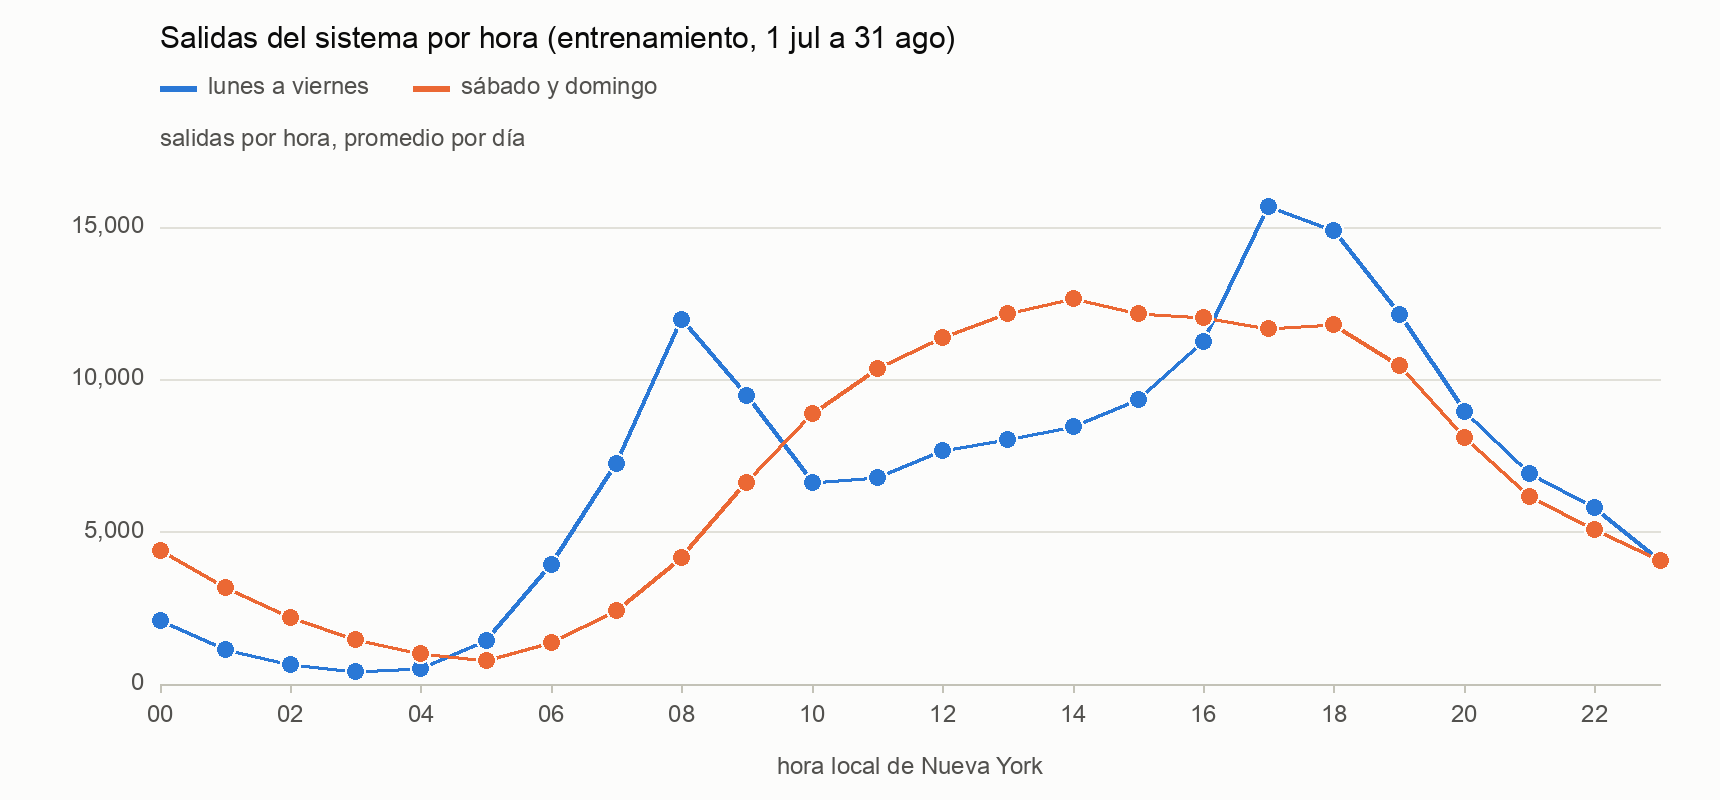

Días promediados: {'lunes a viernes': 44, 'sábado y domingo': 18} (los festivos entre semana cuentan como lunes a viernes)


hora,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
tipo,,,,,,,,,,,,,,,,,,,,,,,,
lunes a viernes,2086,1141,640,408,493,1414,3928,7239,11976,9458,6631,6780,7660,8011,8460,9330,11247,15685,14883,12119,8944,6901,5780,4062
sábado y domingo,4382,3162,2193,1449,994,768,1360,2405,4162,6628,8881,10352,11365,12159,12660,12159,12030,11667,11790,10454,8097,6148,5083,4058


In [12]:
# Salidas del sistema por hora local, promedio por día. Solo con el tramo de entrenamiento.
ent = datos.tramos["entrenamiento"]
perfil = con.execute(f"""
    WITH por_dia AS (
        SELECT CAST(ts_hour AS DATE) AS dia, hour(ts_hour) AS hora, sum(departures) AS salidas
        FROM '{SH}' WHERE ts_hour >= ? AND ts_hour < ? GROUP BY 1, 2)
    SELECT hora, CASE WHEN dayofweek(dia) IN (0, 6) THEN 'sábado y domingo' ELSE 'lunes a viernes' END AS tipo,
           avg(salidas) AS salidas_por_hora, count(*) AS dias
    FROM por_dia GROUP BY 1, 2 ORDER BY 1, 2""", [ent.start, ent.end]).df()
tabla = perfil.pivot(index="hora", columns="tipo", values="salidas_por_hora")
grafica(
    [{"nombre": "lunes a viernes", "x": tabla.index, "y": tabla["lunes a viernes"], "color": AZUL},
     {"nombre": "sábado y domingo", "x": tabla.index, "y": tabla["sábado y domingo"], "color": NARANJA}],
    "Salidas del sistema por hora (entrenamiento, 1 jul a 31 ago)", "hora local de Nueva York", "salidas por hora, promedio por día",
    [(h, f"{h:02d}") for h in range(0, 24, 2)])
print("Días promediados:", perfil.groupby("tipo")["dias"].max().to_dict(), "(los festivos entre semana cuentan como lunes a viernes)")
display(tabla.round(0).astype(int).T)

Entre semana se ven los dos picos de traslado al trabajo (08:00 y 17:00 a 18:00); en fin de
semana hay una sola joroba, de mediodía a media tarde. Por eso la línea base promedia por
estación, **día de la semana** y hora.

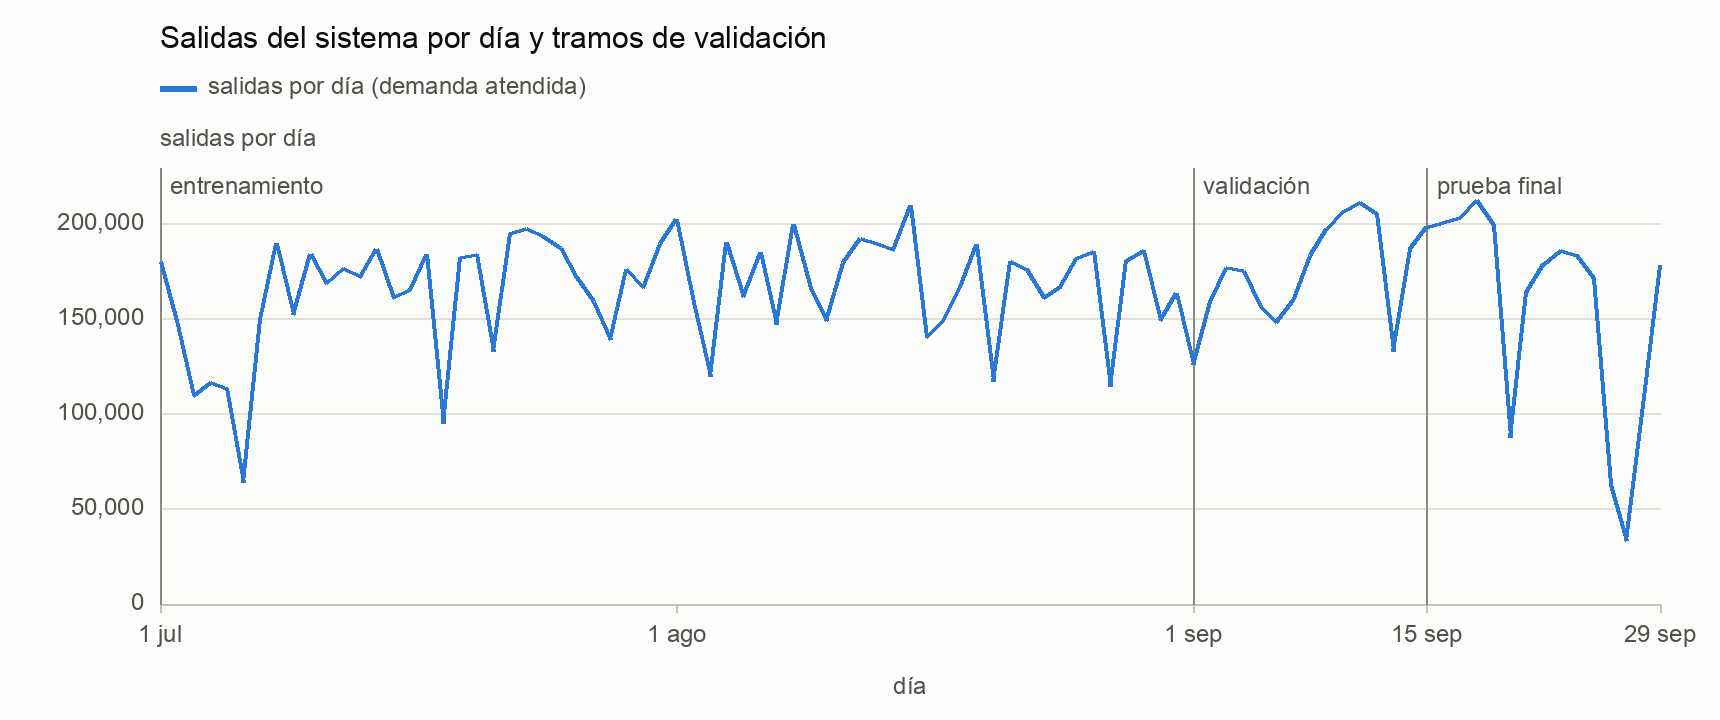

,días,salidas_por_día_media,mínimo,máximo
tramo,,,,
entrenamiento,62,"165,026","63,901","209,340"
validación,14,"173,138","125,936","211,023"
prueba final,15,"157,480","33,303","212,270"


In [13]:
# Salidas por día en todo el periodo, con los tres tramos.
dias = con.execute(f"SELECT CAST(ts_hour AS DATE) AS dia, sum(departures) AS salidas FROM '{SH}' GROUP BY 1 ORDER BY 1").df()
dias["dia"] = pd.to_datetime(dias["dia"])
pos = lambda fecha: (pd.Timestamp(fecha) - dias["dia"].iloc[0]).days
t = datos.tramos
grafica(
    [{"nombre": "salidas por día (demanda atendida)", "x": [pos(x) for x in dias["dia"]], "y": dias["salidas"], "color": AZUL}],
    "Salidas del sistema por día y tramos de validación", "día", "salidas por día",
    [(pos(x), e) for x, e in [("2026-07-01", "1 jul"), ("2026-08-01", "1 ago"), ("2026-09-01", "1 sep"), ("2026-09-15", "15 sep"), ("2026-09-29", "29 sep")]],
    lineas_v=[(pos(t["entrenamiento"].inicio), "entrenamiento"), (pos(t["validacion"].inicio), "validación"), (pos(t["prueba"].inicio), "prueba final")],
    alto=360)
resumen = dias.assign(tramo=pd.cut(dias["dia"], [pd.Timestamp(t["entrenamiento"].inicio) - pd.Timedelta(days=1), pd.Timestamp(t["entrenamiento"].fin),
                                                pd.Timestamp(t["validacion"].fin), pd.Timestamp(t["prueba"].fin)],
                                   labels=["entrenamiento", "validación", "prueba final"]))
display(resumen.groupby("tramo", observed=True)["salidas"].agg(días="count", salidas_por_día_media="mean", mínimo="min", máximo="max").round(0).astype(int).map(miles))

Hay días con mucho menos uso que los de su misma semana. No se contrastó con clima ni con otra
fuente. La gráfica es descriptiva: ninguna decisión de modelado se ajustó mirando el tramo de
prueba final.

## 10. Lo que se sabe que es imperfecto

- **Solo hay demanda atendida.** Nada aquí mide la demanda que no se pudo atender.
- **Ceros que no son demanda cero.** Una estación cerrada varios días sigue teniendo filas en
  cero dentro de su tramo (ver la celda siguiente). El dato no dice por qué.
- **La capacidad es la de la captura de GBFS, no la del periodo.**
- **3 grupos de ids sin unir** quedan como estaciones separadas; si en realidad son la misma
  estación, su historia está partida en dos ids. Una estación reubicada también recibe un id
  nuevo y parte su historia.
- **Llegadas con nombre pero sin id** no se cuentan como llegada.
- Las comprobaciones internas de la corrida (30, todas cumplidas) están en la sección 7 de
  `data/processed/reports/limpieza.md`.

In [14]:
z = limpieza["station_hour"]["ceros_en_rachas_largas"]
print(f"Filas en rachas de {z['horas_minimas_de_la_racha']} horas o más sin ningún viaje: {miles(z['filas'])} "
      f"({pct(z['filas'] / limpieza['station_hour']['filas'], 2)} de la tabla), en {z['rachas']} rachas de {z['estaciones']} estaciones.")
comp = pd.DataFrame(limpieza["comprobaciones"])
print(f"Comprobaciones de la corrida: {int(comp['cumple'].sum())} de {len(comp)} cumplen.")
con.close()

Filas en rachas de 72 horas o más sin ningún viaje: 40,323 (0.80 % de la tabla), en 138 rachas de 120 estaciones.
Comprobaciones de la corrida: 30 de 30 cumplen.
